# 게임 설계 실습: 레드 드래곤 토벌 RPG

> **기획 미션:** 기획서를 읽고 **상속(IS-A)** 과 **구성(HAS-A)** 기반으로 클래스를 설계하세요.

전사 '아서'가 화염검 한 자루를 들고 던전에 들어갑니다. 슬라임과 골렘을 쓰러뜨리며 성장하고, 전리품을 모아 최종 보스 **레드 드래곤**에 도전합니다. 그런데 드래곤은 불 속성이라 화염검이 잘 통하지 않습니다.

**밸런스 표**

| 대상 | 체력 | 속성 | 경험치 | 드롭 |
| --- | --- | --- | --- | --- |
| Warrior(아서) | 150 | (무기 따라감) | - | 시작 무기: 화염검 (공격력 30, 불) |
| Slime | 40 | 풀 | 60 | 물의 창 (공격력 25, 물) |
| Golem | 120 | 풀 | 90 | 강화석 |
| Dragon (보스) | 300 | 불 | 500 | - |

**관계 요약**

| 관계 | 종류 |
| --- | --- |
| Monster, Character → GameObject | 상속 (IS-A) |
| Slime, Golem, Dragon → Monster | 상속 (IS-A) |
| Warrior → Character | 상속 (IS-A) |
| Weapon → Item | 상속 (IS-A) |
| Monster, Character → HP | 구성 (HAS-A) |
| Weapon → Element | 구성 (HAS-A) |
| Character → Level, Inventory, Weapon | 구성 (HAS-A) |
| Monster → Item (drop) | 구성 (HAS-A) |


---
## 설계도와 클래스 정의 순서

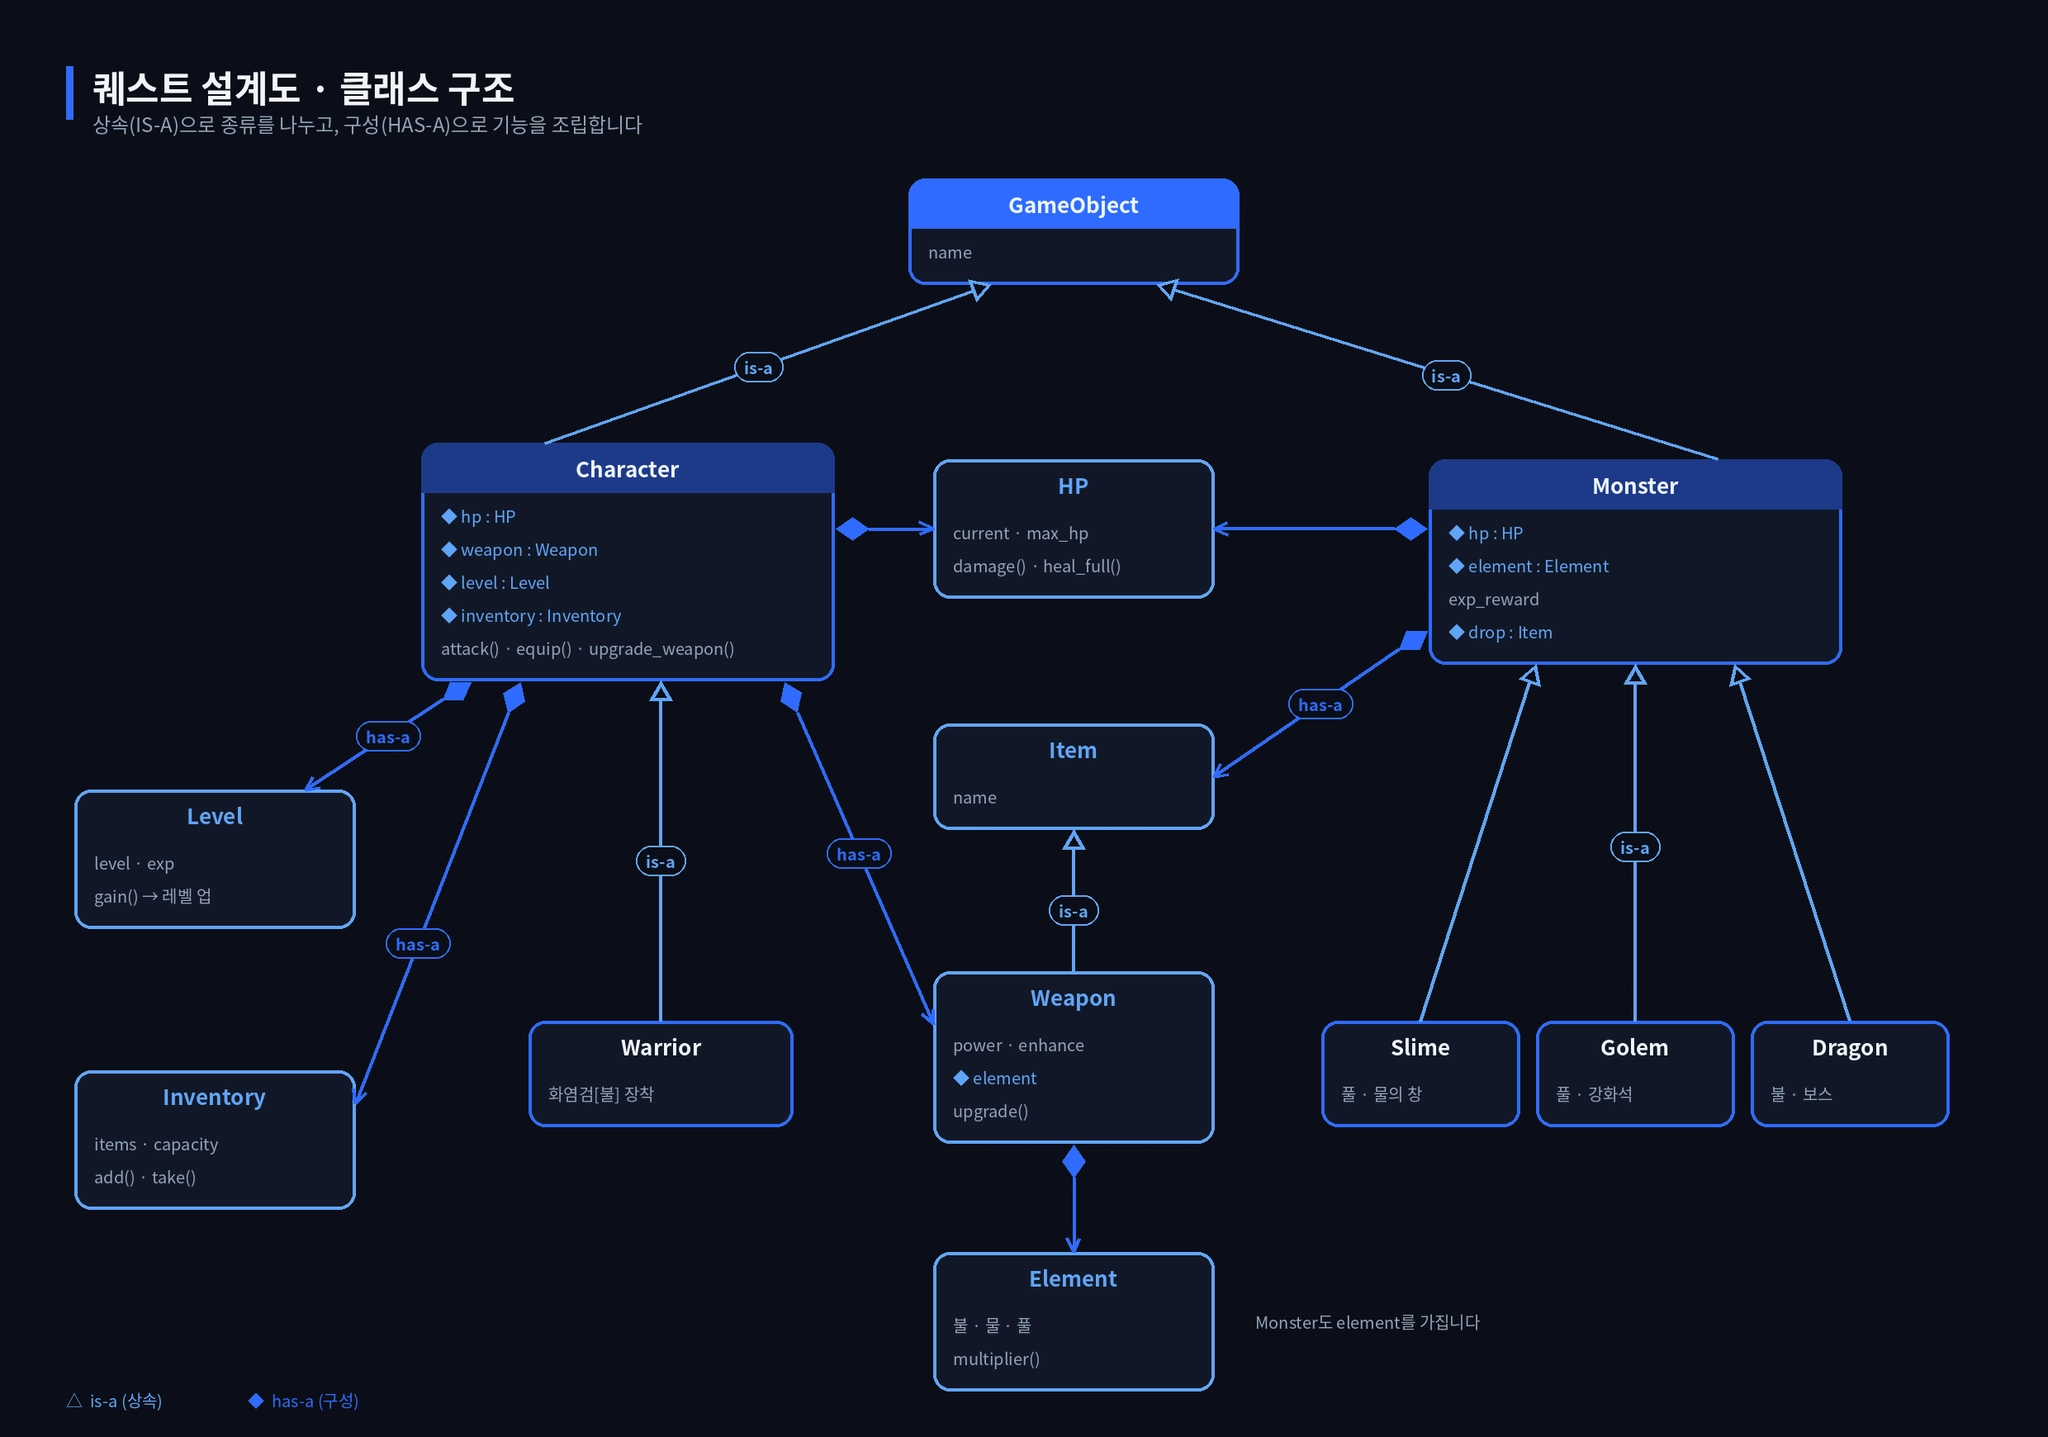

**13개 클래스는 퀘스트 순서대로 정의합니다.**

| 퀘스트 | 정의하는 클래스 | 관계 |
| --- | --- | --- |
| 1 | GameObject, HP, Item, Monster, Slime, Golem, Dragon | Monster → GameObject, 몬스터 3종 → Monster (IS-A) |
| 2 | Element, Weapon | Weapon → Item (IS-A), Weapon ◆ Element (HAS-A) |
| 3 | Level | 단독 부품 |
| 4 | Inventory, Character, Warrior | Character → GameObject, Warrior → Character (IS-A), Character ◆ HP·Weapon·Level·Inventory (HAS-A) |

**왜 이 순서인가?**
- **IS-A는 부모가 먼저:** `class Monster(GameObject):` 는 정의하는 순간 `GameObject` 가 있어야 합니다. 그래서 `GameObject`, `Item` 이 퀘스트 1에 먼저 나오고, 이를 상속하는 `Weapon`(퀘스트 2), `Character`(퀘스트 4)가 뒤따릅니다.
- **HAS-A는 순서와 무관:** `self.hp = HP(max_hp)` 같은 코드는 객체를 **만들 때** 실행되므로 정의 순서에 영향을 주지 않습니다. 그래서 `Slime` 이 퀘스트 2에서 정의되는 `Element`, `Weapon` 을 미리 써도 괜찮습니다. 슬라임 객체는 퀘스트 5에서 처음 만들어집니다.

**진행 방법:** 위에서부터 코드 셀 → 확인 셀 순서로 실행하며 한 퀘스트씩 끝냅니다. 구조본의 `raise NotImplementedError` 는 아직 안 채운 곳에서 바로 멈추게 하는 표시이니, 채우면서 지워 나가세요.


---
## 퀘스트 1. 세계의 기초 만들기 (상속)

- `GameObject(name)` : 모든 게임 객체의 부모
- `HP(max_hp)` : `current`, `max_hp`, `damage(amount)` (0 아래로 내려가지 않음), `heal_full()`, `is_alive()`
- `Item(name)` : 모든 아이템의 부모
- `Monster(GameObject)` : `hp`(HP 객체), `element`, `exp_reward`, `drop`(없으면 `None`)
- `Slime`, `Golem`, `Dragon` 은 `Monster` 를 상속하고, 밸런스 표대로 `super().__init__()` 을 호출

> 참고: `Slime` 안에서 쓰는 `Element`, `Weapon` 은 퀘스트 2에서 만듭니다. `__init__` 안의 코드는 객체를 **만들 때** 실행되므로, 클래스를 먼저 정의해 두는 건 괜찮습니다. 슬라임 객체는 퀘스트 5에서 처음 만듭니다.


In [ ]:
# 모든 게임 객체의 부모
class GameObject:
    def __init__(self, name):
        # 이름 저장
        raise NotImplementedError


# 체력 부품 (Monster, Character가 '갖는다')
class HP:
    def __init__(self, max_hp):
        # 최대 체력 저장, 현재 체력은 최대 체력으로 시작
        raise NotImplementedError

    def damage(self, amount):
        # 현재 체력에서 amount만큼 빼되, 0 아래로는 내려가지 않게
        raise NotImplementedError

    def heal_full(self):
        # 현재 체력을 최대 체력으로 회복
        raise NotImplementedError

    def is_alive(self):
        # 현재 체력이 0보다 크면 True
        raise NotImplementedError


# 모든 아이템의 부모
class Item:
    def __init__(self, name):
        # 이름 저장
        raise NotImplementedError

In [ ]:
# 몬스터는 게임 객체이다 (IS-A)
class Monster(GameObject):
    def __init__(self, name, max_hp, element, exp_reward, drop=None):
        # 부모 생성자로 이름 저장
        # 체력은 HP 객체로 갖는다 (HAS-A)
        # 속성, 경험치 보상, 드롭 아이템 저장
        raise NotImplementedError


class Slime(Monster):
    def __init__(self):
        # 이름 '슬라임', 체력 40, 풀 속성, 경험치 60, 드롭 물의 창(공격력 25, 물)
        raise NotImplementedError


class Golem(Monster):
    def __init__(self):
        # 이름 '골렘', 체력 120, 풀 속성, 경험치 90, 드롭 강화석
        raise NotImplementedError


class Dragon(Monster):
    def __init__(self):
        # 이름 '레드 드래곤', 체력 300, 불 속성, 경험치 500, 드롭 없음
        raise NotImplementedError

In [ ]:
# 확인: HP
hp = HP(100)
hp.damage(30)
print(hp.current, hp.is_alive())
hp.damage(200)
print(hp.current, hp.is_alive())
hp.heal_full()
print(hp.current)

**기대 결과**
```
70 True
0 False
100
```


> 💡 **생각해 보기:** 왜 `Monster` 가 `HP` 를 **상속**하지 않고 **속성으로 가지는** 걸까요?

답변:


---
## 퀘스트 2. 재미 요소 ① 속성 상성

**규칙:** 불 → 풀 → 물 → 불 순서로 강합니다.

- 강한 속성으로 공격 : **×2.0**
- 약한 속성으로 공격 : **×0.5**
- 같은 속성 : **×1.0**

**구현 조건**

- `Element(name)` 클래스, `multiplier(target)` → 배율 반환
- `Weapon(Item)` : 무기는 아이템**이다** (IS-A)
    - `power`, `element` (Element 객체를 **갖는다**, HAS-A), `enhance`(강화 단계, 기본 0)
    - `upgrade()` → 강화 단계 +1, 공격력 +5
    - `__str__()` → `"+1 물의 창[물]"` 형식 (강화 0이면 `"화염검[불]"`)


In [ ]:
class Element:
    # 상성표: key가 value에게 강함 (불 → 풀 → 물 → 불)
    STRONG = {}

    def __init__(self, name):
        # 속성 이름 저장
        raise NotImplementedError

    def multiplier(self, target):
        # 내가 target에게 강하면 2.0
        # target이 나에게 강하면 0.5
        # 그 외(같은 속성)는 1.0
        raise NotImplementedError

In [ ]:
# 무기는 아이템이다 (IS-A), 무기는 속성을 갖는다 (HAS-A)
class Weapon(Item):
    def __init__(self, name, power, element):
        # 부모 생성자로 이름 저장
        # 공격력, 속성(Element 객체), 강화 단계(0) 저장
        raise NotImplementedError

    def upgrade(self):
        # 강화 단계 +1, 공격력 +5
        raise NotImplementedError

    def __str__(self):
        # 강화 0이면 "화염검[불]", 1 이상이면 "+1 물의 창[물]"
        raise NotImplementedError

In [ ]:
# 확인: 속성 상성 + 무기 강화
fire = Element("불")
print(fire.multiplier(Element("풀")), fire.multiplier(Element("물")), fire.multiplier(Element("불")))

spear = Weapon("물의 창", 25, Element("물"))
print(spear)
spear.upgrade()
print(spear, spear.power)

**기대 결과**
```
2.0 0.5 1.0
물의 창[물]
+1 물의 창[물] 30
```


---
## 퀘스트 3. 재미 요소 ② 레벨 업

**규칙:** 다음 레벨까지 필요한 경험치 = `현재 레벨 × 100`. 한 번에 경험치를 많이 받으면 **여러 번 연속 레벨 업**이 가능해야 합니다.

- `Level` 클래스 : `level`(1부터), `exp`(0부터)
- `need()` → 필요 경험치
- `gain(amount)` → 경험치를 더하고, **오른 레벨 수**를 반환
- 캐릭터가 레벨 업하면 **최대 HP +20 (레벨당)**, 체력 완전 회복 → 퀘스트 4의 `attack()` 에서 처리


In [ ]:
class Level:
    def __init__(self):
        # 레벨 1, 경험치 0으로 시작
        raise NotImplementedError

    def need(self):
        # 다음 레벨까지 필요한 경험치 = 현재 레벨 × 100
        raise NotImplementedError

    def gain(self, amount):
        # 1. 경험치를 더한다
        # 2. 경험치가 필요 경험치 이상인 동안 반복 (연속 레벨 업)
        #    - 필요 경험치만큼 빼고, 레벨 +1, 오른 횟수 +1
        # 3. 오른 레벨 수 반환
        raise NotImplementedError

In [ ]:
# 확인: 연속 레벨 업
lv = Level()
print(lv.gain(150), lv.level, lv.exp)
print(lv.gain(500), lv.level, lv.exp)

**기대 결과**
```
1 2 50
2 4 50
```


---
## 퀘스트 4. 재미 요소 ③ 드롭 · 장비 교체 · 강화

- `Inventory(capacity)` : `items` 리스트
    - `add(item)` → 꽉 찼으면 `False`, 아니면 넣고 `True`
    - `take(name)` → 이름이 같은 아이템을 꺼내서 반환 (없으면 `None`)
- `Character(GameObject)` : `hp`, `weapon`, `level`, `inventory(5칸)` 을 **갖는다**
    - `attack(target)` → 전투 로그(문자열 리스트) 반환
    - `equip(name)` → 인벤토리의 무기로 교체, 쓰던 무기는 인벤토리로
    - `upgrade_weapon()` → 강화석 1개를 소모해 현재 무기 강화
- `Warrior(Character)` : 체력 150, 화염검[불] 30으로 시작

**전투 로그 형식**
```
아서의 화염검[불] 공격! 슬라임에게 60 피해 (x2.0)
슬라임 처치! EXP +60
레벨 업! Lv.2 (최대 HP 170)
'물의 창' 획득!
```


In [ ]:
class Inventory:
    def __init__(self, capacity):
        # 최대 칸 수 저장, 아이템 리스트는 빈 리스트로 시작
        raise NotImplementedError

    def add(self, item):
        # 꽉 찼으면 False
        # 아니면 리스트에 넣고 True
        raise NotImplementedError

    def take(self, name):
        # 이름이 같은 아이템을 찾으면 리스트에서 빼고 반환
        # 없으면 None
        raise NotImplementedError

In [ ]:
# 확인: 인벤토리
inv = Inventory(2)
print(inv.add(Item("a")), inv.add(Item("b")), inv.add(Item("c")))
print(inv.take("a").name, inv.take("z"))
print([i.name for i in inv.items])

**기대 결과**
```
True True False
a None
['b']
```


In [ ]:
# 캐릭터는 게임 객체이다 (IS-A)
class Character(GameObject):
    def __init__(self, name, max_hp, weapon):
        # 부모 생성자로 이름 저장
        # hp, weapon, level, inventory(5칸)을 갖는다 (HAS-A)
        raise NotImplementedError

    def attack(self, target):
        # 1. 무기 속성과 대상 속성으로 배율 계산
        # 2. 피해량 = int(공격력 × 배율), 대상 체력 감소
        # 3. 공격 로그: "아서의 화염검[불] 공격! 슬라임에게 60 피해 (x2.0)"
        # 4. 대상이 쓰러졌으면
        #    - 처치 로그: "슬라임 처치! EXP +60"
        #    - 경험치 획득. 레벨이 올랐으면 최대 HP +20 × 오른 레벨 수, 완전 회복
        #      로그: "레벨 업! Lv.2 (최대 HP 170)"
        #    - 드롭 아이템이 있고 인벤토리에 들어가면 로그: "'물의 창' 획득!"
        # 5. 로그 리스트 반환
        raise NotImplementedError

    def equip(self, name):
        # 1. 인벤토리에서 name 아이템을 꺼낸다 (없으면 False)
        # 2. 무기가 아니면 도로 넣고 False
        # 3. 쓰던 무기는 인벤토리에 넣고, 꺼낸 무기로 교체
        # 4. True 반환
        raise NotImplementedError

    def upgrade_weapon(self):
        # 1. 인벤토리에서 강화석을 꺼낸다 (없으면 False)
        # 2. 현재 무기를 강화하고 True 반환
        raise NotImplementedError

In [ ]:
# 전사는 캐릭터이다 (IS-A)
class Warrior(Character):
    def __init__(self, name):
        # 체력 150, 시작 무기 화염검(공격력 30, 불)
        raise NotImplementedError

---
## 퀘스트 5. 최종 보스 레이드

아래 시나리오를 실행해 기대 결과와 같은지 확인하세요.


In [ ]:
hero = Warrior("아서")

# 1) 슬라임 사냥
for line in hero.attack(Slime()):
    print(line)
print([i.name for i in hero.inventory.items])
print("---")

# 2) 골렘 사냥 (쓰러질 때까지 공격)
golem = Golem()
while golem.hp.is_alive():
    for line in hero.attack(golem):
        print(line)
print("---")

# 3) 보스전 준비: 무기 교체 + 강화
print(hero.equip("물의 창"), hero.weapon, [i.name for i in hero.inventory.items])
print(hero.upgrade_weapon(), hero.weapon, hero.weapon.power)
print("---")

# 4) 보스전
boss = Dragon()
turn = 0
while boss.hp.is_alive():
    turn += 1
    hero.attack(boss)
print(f"{turn}턴 만에 보스 처치! Lv.{hero.level.level}, EXP {hero.level.exp}")

**기대 결과**
```
아서의 화염검[불] 공격! 슬라임에게 60 피해 (x2.0)
슬라임 처치! EXP +60
'물의 창' 획득!
['물의 창']
---
아서의 화염검[불] 공격! 골렘에게 60 피해 (x2.0)
아서의 화염검[불] 공격! 골렘에게 60 피해 (x2.0)
골렘 처치! EXP +90
레벨 업! Lv.2 (최대 HP 170)
'강화석' 획득!
---
True 물의 창[물] ['강화석', '화염검']
True +1 물의 창[물] 30
---
5턴 만에 보스 처치! Lv.4, EXP 50
```


---
## 🎯 설계 토론 질문

1. 화염검을 그대로 들고 드래곤과 싸우면 몇 턴이 걸릴까요? 물의 창(+1)과 비교해 보세요.

    답변:

2. `Character` 가 `Weapon` 을 **상속**하도록 설계했다면, 보스전 직전에 무기를 바꾸는 기능을 만들 수 있었을까요?

    답변:

3. 새 직업 `Archer`(궁수)와 새 속성 `번개`를 추가하려면 어느 클래스를 고쳐야 할까요?

    답변:
